# Few-Shot Learning — Siamese Network (avec EasyFSL)

Implémentation d'un **Siamese Network** pour le Few-Shot Learning
sur le dataset **Omniglot**, avec une approche d'entraînement épisodique.

Configuration :

- Dataset : Omniglot
- Backbone : ResNet18
- Méthode : Siamese Network
- Distance : Euclidienne
- Loss : Contrastive Loss
- Entraînement : 5-way 1-shot
- Nombre d'épisodes d'entraînement : 1000
- Évaluation : 5-way 1-shot et 5-way 5-shot
- Nombre de query par classe : 5


In [27]:
!pip install -q easyfsl

In [29]:
# IMPORTS
import random
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as tud

import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

# EasyFSL
from easyfsl.samplers import TaskSampler
from easyfsl.datasets import WrapFewShotDataset

**Reproductibilité et utilisation du GPU**

Afin d'obtenir des résultats reproductibles, nous fixons les différentes graines aléatoires utilisées par Python, NumPy et PyTorch.

Nous vérifions également si un GPU CUDA est disponible.

Le GPU permet d'accélérer les opérations de calcul réalisées pendant l'entraînement du réseau.

In [30]:
print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
    print("CUDA :", torch.version.cuda)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device utilisé :", device)

PyTorch : 2.10.0+cu128
CUDA disponible : True
GPU : Tesla T4
CUDA : 12.8
Device utilisé : cuda


In [31]:
# CORRECTIF EASYFSL / PYTORCH
_original_sampler_init = tud.Sampler.__init__

def _patched_sampler_init(self, *args, **kwargs):
    pass

tud.Sampler.__init__ = _patched_sampler_init

In [9]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("Seed :", SEED)

Seed : 42


## 2. Chargement d'Omniglot

Nous utilisons le split officiel d'Omniglot :

- `background=True` : classes utilisées pour l'entraînement
- `background=False` : classes jamais vues utilisées pour le test

Les images sont :

1. converties en 3 canaux afin d'être compatibles avec ResNet18 ;
2. redimensionnées en 84 × 84 ;
3. normalisées.

In [32]:
# PARAMÈTRES DES IMAGES
IMAGE_SIZE = 84

transform = transforms.Compose([
    # Omniglot est en niveaux de gris.
    # ResNet18 attend 3 canaux.
    transforms.Grayscale(num_output_channels=3),

    # Taille classique utilisée en Few-Shot Learning
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    # Conversion en tenseur
    transforms.ToTensor(),

    # Normalisation
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])

In [33]:
# CHARGEMENT D'OMNIGLOT
raw_train_dataset = datasets.Omniglot(
    root="./data",
    background=True,
    download=True,
    transform=transform
)

raw_test_dataset = datasets.Omniglot(
    root="./data",
    background=False,
    download=True,
    transform=transform
)

print("Train (background) :", len(raw_train_dataset), "images")
print("Test (evaluation)  :", len(raw_test_dataset), "images")

100%|██████████| 9.46M/9.46M [00:00<00:00, 301MB/s]
100%|██████████| 6.46M/6.46M [00:00<00:00, 357MB/s]


Train (background) : 19280 images
Test (evaluation)  : 13180 images


**Visualisation d'Omniglot**

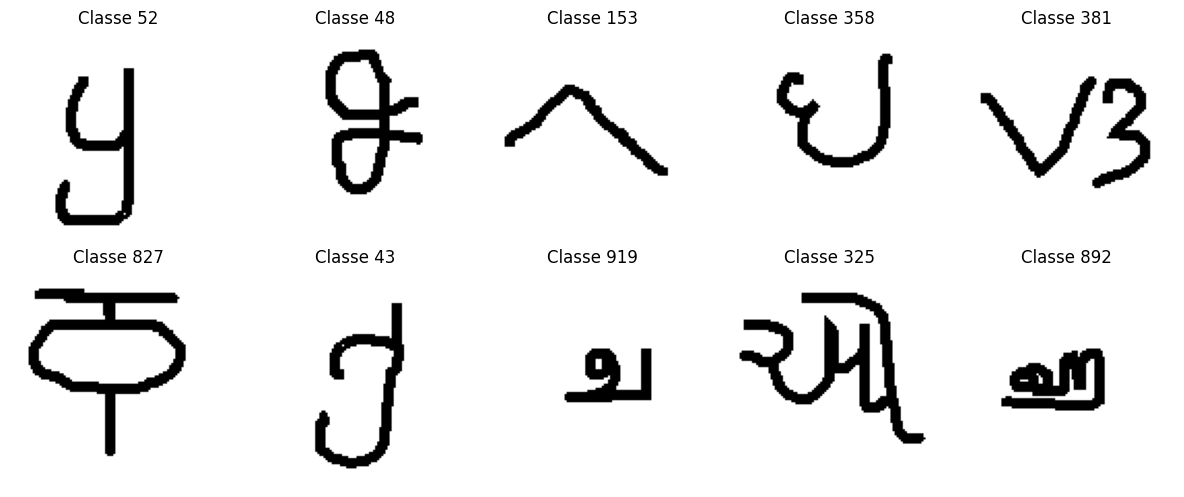

In [34]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax in axes.flat:

    idx = random.randint(
        0,
        len(omniglot_background) - 1
    )

    image, label = omniglot_background[idx]

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Classe {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

#  Adaptation du dataset avec EasyFSL

Dans cette étape, nous adaptons les datasets d'entraînement et de test au format attendu par **EasyFSL**.

La fonction `WrapFewShotDataset` permet d'envelopper le dataset original afin de le rendre compatible avec les outils de génération d'épisodes Few-Shot Learning d'EasyFSL.

Nous créons ainsi deux datasets :

* `train_dataset` pour l'entraînement du Siamese Network ;
* `test_dataset` pour l'évaluation du modèle.

Cette adaptation ne modifie pas les images elles-mêmes. Elle permet principalement à EasyFSL d'accéder aux informations nécessaires à la construction des tâches Few-Shot.

Le processus peut être résumé ainsi :

$$
\text{Dataset Omniglot original}
\rightarrow
\text{WrapFewShotDataset}
\rightarrow
\text{Dataset compatible EasyFSL}
$$

Les deux datasets obtenus seront ensuite utilisés pour générer les épisodes d'entraînement et de test.


In [35]:
# WRAPPER EASYFSL
train_dataset = WrapFewShotDataset(raw_train_dataset)
test_dataset = WrapFewShotDataset(raw_test_dataset)

print("Dataset d'entraînement prêt.")
print("Dataset de test prêt.")

Scrolling dataset's labels...: 100%|██████████| 13180/13180 [00:09<00:00, 1354.74it/s]

Dataset d'entraînement prêt.
Dataset de test prêt.


## 3. Construction des épisodes

Un épisode est défini par :

- N-way : nombre de classes ;
- K-shot : nombre d'images support par classe ;
- Q-query : nombre d'images query par classe.

Dans ce projet :

N-way = 5

Nous utiliserons :

- 5-way 1-shot pour l'entraînement et l'évaluation ;
- 5-way 5-shot pour l'évaluation.

Le nombre de query est toujours égal à 5.

In [37]:
# CRÉATION D'UN DATALOADER ÉPISODIQUE
def create_episodic_loader(
    dataset,
    n_way,
    n_shot,
    n_query,
    n_tasks,
    num_workers=2
):
    
    # TaskSampler crée automatiquement les épisodes
    sampler = TaskSampler(
        dataset,
        n_way=n_way,
        n_shot=n_shot,
        n_query=n_query,
        n_tasks=n_tasks
    )

    # DataLoader utilisant les épisodes comme batchs
    loader = DataLoader(
        dataset,
        batch_sampler=sampler,
        num_workers=num_workers,
        pin_memory=True,
        collate_fn=sampler.episodic_collate_fn
    )

    return loader, sampler

EasyFSL va gérer nos épisodes Few-Shot, mais l'entraînement Siamese reste un apprentissage par paires.

On crée donc un dataset de paires.

**Vérifier un épisode 5-way 1-shot**

In [38]:
# TEST D'UN ÉPISODE
_, quick_sampler = create_episodic_loader(
    train_dataset,
    n_way=5,
    n_shot=1,
    n_query=5,
    n_tasks=1
)

quick_loader = DataLoader(
    train_dataset,
    batch_sampler=quick_sampler,
    collate_fn=quick_sampler.episodic_collate_fn
)

(
    support_images,
    support_labels,
    query_images,
    query_labels,
    class_ids
) = next(iter(quick_loader))


print("Support :", support_images.shape)
print("Support labels :", support_labels.shape)

print("Query :", query_images.shape)
print("Query labels :", query_labels.shape)

print("Classes :", class_ids)

Support : torch.Size([5, 3, 84, 84])
Support labels : torch.Size([5])
Query : torch.Size([25, 3, 84, 84])
Query labels : torch.Size([25])
Classes : [225, 459, 429, 603, 284]


EasyFSL propose également des architectures prédéfinies, dont ResNet18.

Mais ici, pour le Siamese, nous avons utiliser directement le ResNet18 de torchvision.

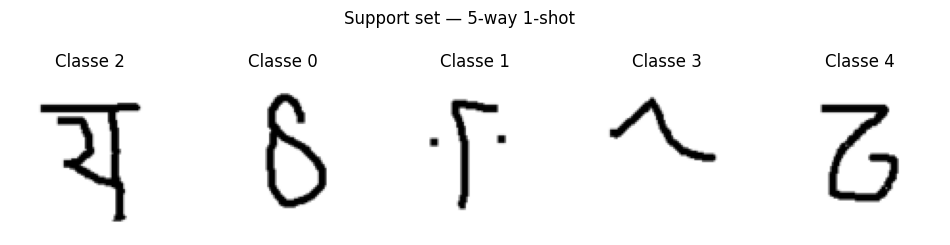

In [40]:
# VISUALISATION D'UN ÉPISODE
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i in range(5):

    # Image
    image = support_images[i].permute(1, 2, 0)

    # Revenir approximativement à [0,1]
    image = image * 0.5 + 0.5

    axes[i].imshow(image.squeeze())
    axes[i].set_title(f"Classe {support_labels[i].item()}")
    axes[i].axis("off")

plt.suptitle("Support set — 5-way 1-shot")
plt.show()

In [41]:
# ENCODER RESNET18
resnet = models.resnet18(weights=None)

# Remplacer la dernière couche de classification
# par une couche produisant un embedding.
FEATURE_DIMENSION = 128

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    FEATURE_DIMENSION
)

print(resnet)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

#  Architecture du Siamese Network

Le **Siamese Network** est une architecture conçue pour comparer deux images afin de déterminer si elles sont similaires ou différentes.

Le réseau contient deux branches qui utilisent **le même encodeur**. Dans notre implémentation, cet encodeur est basé sur **ResNet18**.

Pour deux images $x_1$ et $x_2$, le même encodeur $f_{\theta}$ est appliqué aux deux images :

$$
z_1 = f_{\theta}(x_1)
$$

$$
z_2 = f_{\theta}(x_2)
$$

où :

* $x_1$ et $x_2$ sont les deux images de la paire ;
* $f_{\theta}$ représente l'encodeur ;
* $\theta$ représente les paramètres appris par l'encodeur ;
* $z_1$ et $z_2$ sont les embeddings obtenus.

Le point essentiel est que les deux branches **partagent exactement les mêmes paramètres**. Il ne s'agit donc pas de deux réseaux indépendants.

L'architecture peut être représentée de la manière suivante :

$$
x_1
\rightarrow
f_{\theta}
\rightarrow
z_1
$$

$$
x_2
\rightarrow
f_{\theta}
\rightarrow
z_2
$$

Les deux embeddings sont ensuite utilisés pour calculer une distance et déterminer le degré de similarité entre les deux images.

Dans notre implémentation, la classe `SiameseNetwork` contient trois fonctions principales :

* `forward_once(x)` : transforme une image en embedding ;
* `forward(x1, x2)` : transforme les deux images de la paire avec le même encodeur ;
* `get_embedding(x)` : permet d'obtenir directement l'embedding d'une image.

Le principe général est donc :

$$
(x_1,x_2)
\rightarrow
\text{Encodeur partagé}
\rightarrow
(z_1,z_2)
\rightarrow
\text{Distance}
\rightarrow
\text{Décision de similarité}
$$

Cette architecture permet au modèle d'apprendre une représentation dans laquelle les images d'une même classe sont proches et celles de classes différentes sont éloignées.


In [42]:
# SIAMESE NETWORK
class SiameseNetwork(nn.Module):

    def __init__(self, encoder):
        super().__init__()

        # Encoder partagé par les deux branches
        self.encoder = encoder

    def forward_once(self, x):
        """
        Transforme une image en embedding.
        """
        return self.encoder(x)

    def forward(self, x1, x2):
        """
        Traite deux images avec le même encoder.
        """

        embedding1 = self.forward_once(x1)
        embedding2 = self.forward_once(x2)

        return embedding1, embedding2

    def get_embedding(self, x):
        """
        Retourne directement les embeddings.
        """
        return self.encoder(x)

In [46]:
# CRÉATION DU MODÈLE
siamese_model = SiameseNetwork(resnet).to(device)

print(siamese_model)

SiameseNetwork(
  (encoder): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, tr

# Distance euclidienne entre les embeddings

Après avoir obtenu les embeddings des deux images d'une paire, nous devons mesurer leur proximité dans l'espace de représentation.

Nous utilisons pour cela la **distance euclidienne**.

Pour deux embeddings $z_1$ et $z_2$, elle est définie par :

$$
D(z_1,z_2)
=
\|z_1-z_2\|_2
$$

Cette distance mesure l'écart entre les deux vecteurs dans l'espace d'embedding.

Dans notre modèle :

$$
z_1=f_{\theta}(x_1)
$$

et :

$$
z_2=f_{\theta}(x_2)
$$

La distance devient donc :

$$
D=
\|f_{\theta}(x_1)-f_{\theta}(x_2)\|_2
$$

### Interprétation

* Une **petite distance** indique que les deux images ont des représentations similaires.
* Une **grande distance** indique que les deux images ont des représentations différentes.

Cette distance est ensuite utilisée par la **Contrastive Loss** pour entraîner le réseau.

Pour une paire positive, le modèle cherche à minimiser :

$$
D \rightarrow 0
$$

Pour une paire négative, le modèle cherche à obtenir une distance suffisamment grande, en fonction de la marge définie dans la fonction de perte.

Dans le code, `F.pairwise_distance` calcule cette distance entre les deux embeddings pour chaque paire.

Le processus est donc :

$$
\text{Image 1}
\rightarrow
z_1
$$

$$
\text{Image 2}
\rightarrow
z_2
$$

$$
(z_1,z_2)
\rightarrow
\text{Distance euclidienne}
\rightarrow
D
$$

La valeur $D$ sera ensuite utilisée pour calculer la **Contrastive Loss**.


In [47]:
# DISTANCE EUCLIDIENNE
def euclidean_distance(embedding1, embedding2):

    return F.pairwise_distance(
        embedding1,
        embedding2
    )

# Fonction de perte contrastive (Contrastive Loss)

La **Contrastive Loss** est la fonction de perte utilisée pour entraîner notre Siamese Network. Son objectif est d'apprendre un espace de représentation dans lequel les images de même classe sont proches et les images de classes différentes sont suffisamment éloignées.

Pour une paire d'images, on note :

- $D$ : la distance euclidienne entre les deux embeddings ;
- $y = 1$ : les deux images appartiennent à la même classe ;
- $y = 0$ : les deux images appartiennent à des classes différentes ;
- $m$ : la marge (*margin*), fixée ici à $1.0$.

La fonction de perte utilisée est :

$$
\mathcal{L}
=
\frac{1}{2}
\left[
yD^2
+
(1-y)\max(0,m-D)^2
\right]
$$

### Cas 1 : images de même classe

Lorsque $y=1$, seule la partie positive de la perte est active :

$$
\mathcal{L}
=
\frac{1}{2}D^2
$$

Le modèle est donc encouragé à **réduire la distance** entre les deux embeddings, idéalement vers zéro.

### Cas 2 : images de classes différentes

Lorsque $y=0$, la perte devient :

$$
\mathcal{L}
=
\frac{1}{2}\max(0,m-D)^2
$$

Si $D < m$, une pénalité est appliquée afin d'éloigner les deux embeddings.

Si $D \geq m$, la perte devient nulle :

$$
\mathcal{L}=0
$$

Le modèle n'a donc pas besoin d'éloigner davantage les images déjà suffisamment séparées.

### Rôle de la marge

Dans notre implémentation :

$$
m=1.0
$$

La marge définit la distance minimale souhaitée entre les embeddings de deux classes différentes.

La fonction `torch.clamp(self.margin - distance, min=0.0)` permet de conserver uniquement une pénalité lorsque la distance est inférieure à cette marge.

Enfin, la moyenne des pertes calculées pour toutes les paires est retournée par `loss.mean()`.

Ainsi, l'apprentissage du Siamese Network cherche à obtenir la structure suivante dans l'espace des embeddings :

$$
\text{Même classe}
\Rightarrow
D \rightarrow 0
$$

$$
\text{Classes différentes}
\Rightarrow
D \geq m
$$

In [49]:
# CONTRASTIVE LOSS
class ContrastiveLoss(nn.Module):

    def __init__(self, margin=1.0):
        super().__init__()

        self.margin = margin

    def forward(self, distance, label):

        # Pour les mêmes classes :
        # on veut une distance proche de 0
        positive_loss = label * torch.pow(distance, 2)

        # Pour les classes différentes :
        # on veut une distance supérieure au margin
        negative_loss = (
            (1 - label)
            * torch.pow(
                torch.clamp(
                    self.margin - distance,
                    min=0.0
                ),
                2
            )
        )

        loss = 0.5 * (
            positive_loss + negative_loss
        )

        return loss.mean()

# Optimisation du modèle

Pour entraîner le Siamese Network, nous utilisons l'optimiseur **Adam**.

L'optimiseur permet de mettre à jour les paramètres du modèle afin de minimiser la **Contrastive Loss**.

Nous utilisons les paramètres suivants :

- **Learning rate** : $10^{-4}$
- **Weight decay** : $10^{-5}$

Le learning rate contrôle l'amplitude des mises à jour des paramètres :

$$
\theta \leftarrow \theta - \eta \nabla_{\theta}\mathcal{L}
$$

où $\eta$ représente le learning rate.

Le paramètre `weight_decay` ajoute une régularisation afin de limiter des valeurs trop importantes des paramètres et de réduire le risque de surapprentissage.

Le modèle et la fonction de perte utilisés pour l'apprentissage sont donc :

$$
\text{Siamese Network}
\rightarrow
\text{Distance euclidienne}
\rightarrow
\text{Contrastive Loss}
\rightarrow
\text{Adam}
\rightarrow
\text{Mise à jour des paramètres}
$$

In [50]:
# OPTIMISEUR
optimizer = optim.Adam(
    siamese_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

criterion = ContrastiveLoss(
    margin=1.0
)

In [51]:
# PARAMÈTRES D'ENTRAÎNEMENT
N_WAY = 5

# Entraînement en 5-way 1-shot
N_SHOT = 1

# 5 images query par classe
N_QUERY = 5

# Exactement 1000 épisodes
N_TRAINING_EPISODES = 1000

print("N-way :", N_WAY)
print("N-shot :", N_SHOT)
print("N-query :", N_QUERY)
print("Training episodes :", N_TRAINING_EPISODES)

N-way : 5
N-shot : 1
N-query : 5
Training episodes : 1000


# Construction du DataLoader épisodique

Le Few-Shot Learning repose sur un apprentissage **épisodique**. Au lieu d'entraîner le modèle uniquement avec des mini-batchs classiques, nous construisons des épisodes qui reproduisent la structure du problème Few-Shot rencontré lors de l'évaluation.

Pour notre expérience, chaque épisode contient :

- **5 classes** : $N$-way avec $N=5$ ;
- **1 exemple de support par classe** : $K$-shot avec $K=1$ ;
- **5 exemples de requête par classe**.

Ainsi, un épisode contient :

$$
5 \times 1 = 5
$$

images de support et :

$$
5 \times 5 = 25
$$

images de requête.

Le DataLoader épisodique est construit à l'aide d'**EasyFSL**. Le `TaskSampler` génère automatiquement les épisodes à partir du dataset d'entraînement.

Dans cette expérience, nous générons :

$$
1000
$$

épisodes d'entraînement.

La structure générale d'un épisode est donc :

$$
\text{Support Set}
+
\text{Query Set}
\rightarrow
\text{Épisode Few-Shot}
$$

Le `train_loader` permettra ensuite d'itérer sur ces épisodes pendant la phase d'entraînement du Siamese Network.

In [52]:
# TRAINING EPISODIC LOADER
train_loader, train_sampler = create_episodic_loader(
    train_dataset,
    n_way=N_WAY,
    n_shot=N_SHOT,
    n_query=N_QUERY,
    n_tasks=N_TRAINING_EPISODES
)

## Création de paires équilibrées pour le Siamese Network

Dans un **Siamese Network**, le modèle reçoit deux images à la fois et apprend à déterminer si elles appartiennent à la **même classe** ou à des **classes différentes**.

Nous construisons donc deux types de paires :

- **Paires positives (label = 1)** : les deux images appartiennent à la même classe.
- **Paires négatives (label = 0)** : les deux images appartiennent à deux classes différentes.

Pour obtenir un dataset équilibré, nous générons le même nombre de paires positives et négatives.

La fonction `create_pairs()` réalise les étapes suivantes :

1. Parcourir toutes les classes disponibles.
2. Pour chaque classe, sélectionner aléatoirement deux images différentes afin de créer des paires positives.
3. Générer le même nombre de paires négatives en sélectionnant deux classes différentes, puis une image dans chaque classe.
4. Regrouper les paires positives et négatives.
5. Mélanger aléatoirement toutes les paires afin d'éviter que le modèle rencontre d'abord toutes les paires d'une même catégorie.

Chaque paire est représentée sous la forme :

`(indice_image_1, indice_image_2, label)`

où :
- `label = 1` → même classe ;
- `label = 0` → classes différentes.

Cette étape permet de préparer les données nécessaires à l'entraînement du **Siamese Network**, qui va apprendre une représentation où les images similaires sont proches et les images différentes sont éloignées.

In [53]:
# CRÉATION DE PAIRES ÉQUILIBRÉES
def create_pairs(images, labels, pairs_per_class=5):

    positive_pairs = []
    negative_pairs = []

    unique_classes = torch.unique(labels)

    # --------------------------------
    # PAIRES POSITIVES
    # --------------------------------

    for class_id in unique_classes:

        indices = torch.where(
            labels == class_id
        )[0].tolist()

        for _ in range(pairs_per_class):

            i, j = random.sample(indices, 2)

            positive_pairs.append((i, j, 1))

    # --------------------------------
    # PAIRES NÉGATIVES
    # --------------------------------

    for _ in range(len(positive_pairs)):

        class1, class2 = random.sample(
            unique_classes.tolist(),
            2
        )

        indices1 = torch.where(
            labels == class1
        )[0].tolist()

        indices2 = torch.where(
            labels == class2
        )[0].tolist()

        i = random.choice(indices1)
        j = random.choice(indices2)

        negative_pairs.append((i, j, 0))

    pairs = positive_pairs + negative_pairs

    random.shuffle(pairs)

    return pairs

In [54]:
# ENTRAÎNEMENT D'UN ÉPISODE
def train_one_episode(
    model,
    support_images,
    support_labels,
    query_images,
    query_labels,
    optimizer,
    criterion
):

    model.train()

    optimizer.zero_grad()

    # --------------------------------
    # Combiner support et query
    # --------------------------------

    images = torch.cat(
        [support_images, query_images],
        dim=0
    )

    labels = torch.cat(
        [support_labels, query_labels],
        dim=0
    )

    images = images.to(device)
    labels = labels.to(device)

    # --------------------------------
    # Calculer tous les embeddings
    # --------------------------------

    embeddings = model.get_embedding(images)

    # --------------------------------
    # Créer les paires
    # --------------------------------

    pairs = create_pairs(
        images,
        labels,
        pairs_per_class=5
    )

    indices1 = torch.tensor(
        [p[0] for p in pairs],
        device=device
    )

    indices2 = torch.tensor(
        [p[1] for p in pairs],
        device=device
    )

    pair_labels = torch.tensor(
        [p[2] for p in pairs],
        dtype=torch.float32,
        device=device
    )
    # Embeddings des paires
   embedding1 = embeddings[indices1]
    embedding2 = embeddings[indices2]

    # Distance
    distances = euclidean_distance(
        embedding1,
        embedding2
    )
    # Contrastive Loss
    loss = criterion(
        distances,
        pair_labels
    )

    # Backpropagation

    loss.backward()

    optimizer.step()

    return loss.item()

In [55]:
# ENTRAÎNEMENT ÉPISODIQUE
training_losses = []

for episode_index, (
    support_images,
    support_labels,
    query_images,
    query_labels,
    _
) in enumerate(train_loader):

    loss = train_one_episode(
        siamese_model,
        support_images,
        support_labels,
        query_images,
        query_labels,
        optimizer,
        criterion
    )

    training_losses.append(loss)

    # Affichage tous les 100 épisodes
    if (episode_index + 1) % 100 == 0:

        mean_loss = np.mean(
            training_losses[-100:]
        )

        print(
            f"Episode [{episode_index + 1}/{N_TRAINING_EPISODES}] "
            f"Loss: {mean_loss:.4f}"
        )

Episode [100/1000] Loss: 0.5628
Episode [200/1000] Loss: 0.1257
Episode [300/1000] Loss: 0.0985
Episode [400/1000] Loss: 0.0869
Episode [500/1000] Loss: 0.0806
Episode [600/1000] Loss: 0.0758
Episode [700/1000] Loss: 0.0712
Episode [800/1000] Loss: 0.0736
Episode [900/1000] Loss: 0.0692
Episode [1000/1000] Loss: 0.0695


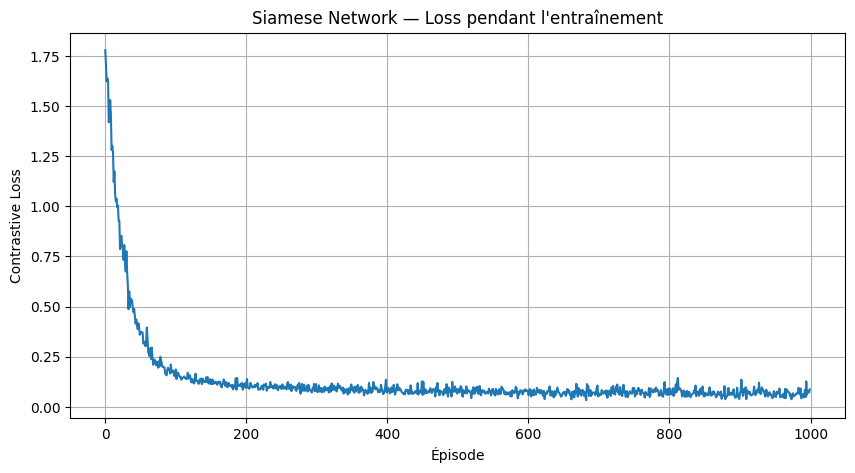

In [56]:
# COURBE DE LOSS
plt.figure(figsize=(10, 5))

plt.plot(training_losses)

plt.xlabel("Épisode")
plt.ylabel("Contrastive Loss")

plt.title(
    "Siamese Network — Loss pendant l'entraînement"
)

plt.grid()

plt.show()

## 5. Évaluation

Le modèle est évalué sur le split `background=False` d'Omniglot.

Deux configurations sont utilisées :

1. 5-way 1-shot
2. 5-way 5-shot

Dans les deux cas :

- N-way = 5
- N-query = 5


In [57]:
# PRÉDICTION D'UNE QUERY
def predict_query(
    model,
    support_images,
    support_labels,
    query_image
):

    model.eval()

    with torch.no_grad():

        # Embedding du support
        support_embeddings = model.get_embedding(
            support_images.to(device)
        )

        # Embedding de la query
        query_embedding = model.get_embedding(
            query_image.unsqueeze(0).to(device)
        )

        predictions = []

        unique_classes = torch.unique(
            support_labels
        )

        for class_id in unique_classes:

            # Embeddings de cette classe
            class_embeddings = support_embeddings[
                support_labels.to(device) == class_id
            ]

            # Même query comparée aux supports
            repeated_query = query_embedding.repeat(
                class_embeddings.size(0),
                1
            )

            distances = euclidean_distance(
                repeated_query,
                class_embeddings
            )

            # Distance moyenne à la classe
            mean_distance = distances.mean()

            predictions.append(
                (class_id.item(), mean_distance.item())
            )

        # Classe avec la distance minimale
        prediction = min(
            predictions,
            key=lambda x: x[1]
        )[0]

    return prediction

In [58]:
# ÉVALUATION FEW-SHOT
def evaluate_siamese(
    model,
    dataset,
    n_way,
    n_shot,
    n_query=5,
    n_tasks=600
):

    loader, _ = create_episodic_loader(
        dataset,
        n_way=n_way,
        n_shot=n_shot,
        n_query=n_query,
        n_tasks=n_tasks
    )

    all_predictions = []
    all_targets = []

    model.eval()

    with torch.no_grad():

        for (
            support_images,
            support_labels,
            query_images,
            query_labels,
            _
        ) in loader:

            # Chaque query est classée séparément
            for i in range(len(query_images)):

                prediction = predict_query(
                    model,
                    support_images,
                    support_labels,
                    query_images[i]
                )

                target = query_labels[i].item()

                all_predictions.append(prediction)
                all_targets.append(target)

    accuracy = np.mean(
        np.array(all_predictions)
        == np.array(all_targets)
    )

    return (
        accuracy,
        all_targets,
        all_predictions
    )

In [60]:
# ÉVALUATION FEW-SHOT
def evaluate_siamese(
    model,
    dataset,
    n_way,
    n_shot,
    n_query=5,
    n_tasks=1000
):

    loader, _ = create_episodic_loader(
        dataset,
        n_way=n_way,
        n_shot=n_shot,
        n_query=n_query,
        n_tasks=n_tasks
    )

    all_predictions = []
    all_targets = []

    model.eval()

    with torch.no_grad():

        for (
            support_images,
            support_labels,
            query_images,
            query_labels,
            _
        ) in loader:

            # Chaque query est classée séparément
            for i in range(len(query_images)):

                prediction = predict_query(
                    model,
                    support_images,
                    support_labels,
                    query_images[i]
                )

                target = query_labels[i].item()

                all_predictions.append(prediction)
                all_targets.append(target)

    accuracy = np.mean(
        np.array(all_predictions)
        == np.array(all_targets)
    )

    return (
        accuracy,
        all_targets,
        all_predictions
    )

In [62]:
# TEST : 5-WAY 1-SHOT
accuracy_1shot, targets_1shot, predictions_1shot = evaluate_siamese(
    siamese_model,
    test_dataset,
    n_way=5,
    n_shot=1,
    n_query=5,
    n_tasks=600
)

print(
    f"Accuracy 5-way 1-shot : "
    f"{accuracy_1shot * 100:.2f}%"
)

Accuracy 5-way 1-shot : 72.19%


In [63]:
# TEST : 5-WAY 5-SHOT
accuracy_5shot, targets_5shot, predictions_5shot = evaluate_siamese(
    siamese_model,
    test_dataset,
    n_way=5,
    n_shot=5,
    n_query=5,
    n_tasks=600
)

print(
    f"Accuracy 5-way 5-shot : "
    f"{accuracy_5shot * 100:.2f}%"
)

Accuracy 5-way 5-shot : 81.91%


In [64]:
# COMPARAISON 1-SHOT / 5-SHOT
print("===================================")
print("       RÉSULTATS SIAMESE")
print("===================================")

print(
    f"5-way 1-shot : "
    f"{accuracy_1shot * 100:.2f}%"
)

print(
    f"5-way 5-shot : "
    f"{accuracy_5shot * 100:.2f}%"
)

       RÉSULTATS SIAMESE
5-way 1-shot : 72.19%
5-way 5-shot : 81.91%


In [65]:
# MÉTRIQUES
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [67]:
# MÉTRIQUES 5-WAY 1-SHOT
accuracy = accuracy_score(
    targets_1shot,
    predictions_1shot
)

precision = precision_score(
    targets_1shot,
    predictions_1shot,
    average="macro",
    zero_division=0
)

recall = recall_score(
    targets_1shot,
    predictions_1shot,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    targets_1shot,
    predictions_1shot,
    average="macro",
    zero_division=0
)

print("===== 5-WAY 1-SHOT =====")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

===== 5-WAY 1-SHOT =====
Accuracy  : 0.7219
Precision : 0.7223
Recall    : 0.7219
F1-score  : 0.7220


In [68]:
# MÉTRIQUES 5-WAY 5-SHOT
accuracy = accuracy_score(
    targets_5shot,
    predictions_5shot
)

precision = precision_score(
    targets_5shot,
    predictions_5shot,
    average="macro",
    zero_division=0
)

recall = recall_score(
    targets_5shot,
    predictions_5shot,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    targets_5shot,
    predictions_5shot,
    average="macro",
    zero_division=0
)

print("===== 5-WAY 5-SHOT =====")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

===== 5-WAY 5-SHOT =====
Accuracy  : 0.8191
Precision : 0.8191
Recall    : 0.8191
F1-score  : 0.8191
